**ECG Heartbeat Classification on MIT-BIH: complete experiment record**


Contents


1.   Setup and configuration
2.   Data and raw-signal EDA
3.   Experiment 1: heart-rate window classification (negative result: label leakage)
Feature engineering, cached as parquet (Stage 1 beat features, Stage 2 QRS features, RR-context features)
4. Feature-level EDA (data quality, profiling, correlation, patient structure, DS1 vs DS2 drift)
5. Evaluation protocol and helpers
6. Experiment 2: Stage-1 features only
7. Experiment 3: protocol corrections and Stage-2 QRS features (the replication)
8. Experiment 4: extra features (RR context, patient-relative shape)
9. Experiment 5: gradient boosting (XGBoost, LightGBM)
10. Experiment 6: genetic-algorithm stacking and decision weighting for S
11. Final comparison on DS2, plus robustness checks
Conclusions and limitations




In [1]:
##Setting up the dataset and converting it into Pacquet
!pip install shap


In [ ]:
import os, random, warnings, subprocess
from pathlib import Path
from collections import Counter
from itertools import product

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import wfdb, pywt, joblib, shap
from joblib import Parallel, delayed
from scipy.signal import resample_poly
from scipy.stats import skew, kurtosis, ks_2samp
from scipy.ndimage import median_filter
from numpy.polynomial.hermite import hermfit

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import LeaveOneGroupOut, GroupKFold, PredefinedSplit, cross_val_predict
from sklearn.metrics import f1_score, classification_report, confusion_matrix, roc_auc_score
import xgboost as xgb, lightgbm as lgb

%matplotlib inline
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 40)

In [ ]:
AAMI = {**dict.fromkeys(['N', 'L', 'R', 'e', 'j'], 'N'),   # normal, LBBB, RBBB, atrial escape, nodal escape
        **dict.fromkeys(['A', 'a', 'J', 'S'], 'S'),        # supraventricular ectopic
        **dict.fromkeys(['V', 'E'], 'V'),                  # ventricular ectopic
        'F': 'F',                                          # fusion of ventricular and normal
        **dict.fromkeys(['/', 'f', 'Q'], 'Q')}             # paced, fusion of paced and normal, unclassifiable

In [ ]:
DATA_DIR = Path('mitdb')
ART = Path('artifacts')
ART.mkdir(parents=True, exist_ok=True)  # update this path if your downloaded files live elsewhere
ART = Path('artifacts')
ART.mkdir(parents=True, exist_ok=True)
FORCE_REBUILD = False                           # True = recompute every cached parquet / pickle

FS, HALF, HIST = 360, 90, 32                    # sampling rate; half beat window (250 ms); causal normalisation history (beats)

In [ ]:
DS1 = [101,106,108,109,112,114,115,116,118,119,122,124,201,203,205,207,208,209,215,220,223,230]
DS2 = [100,103,105,111,113,117,121,123,200,202,210,212,213,214,219,221,222,228,231,232,233,234]
REC_S_HEAVY, REC_BBB = 232, (214, 219)          # record holding most DS2 S beats; bundle-branch-block / irregular records
RF_TREES, BOOST_TREES, SWEEP = 40, 200, range(1, 11)
GA_POP, GA_GENS = 20, 15
RUN_PROFILING = True
print('FULL | DS1', len(DS1), 'records | DS2', len(DS2), 'records')

FULL | DS1 22 records | DS2 22 records


In [ ]:
def rec_path(rid): return str(DATA_DIR / str(rid))

def record_overview(ids, split):
    rows = []
    for rid in ids:
        h, a = wfdb.rdheader(rec_path(rid)), wfdb.rdann(rec_path(rid), 'atr')
        cnt = Counter(AAMI[s] for s in a.symbol if s in AAMI)
        rows.append(dict(split=split, record=rid, minutes=round(h.sig_len / h.fs / 60, 1), n_beats=sum(cnt.values()),
                         **{k: cnt.get(k, 0) for k in 'NSVFQ'}))
    return pd.DataFrame(rows)

overview = pd.concat([record_overview(DS1, 'DS1'), record_overview(DS2, 'DS2')], ignore_index=True)
display(overview.groupby('split')[list('NSVFQ')].sum())
display(overview.sort_values('S', ascending=False).head(8))

,N,S,V,F,Q
split,,,,,
DS1,45866,944,3788,415,8
DS2,44259,1837,3221,388,7


,split,record,minutes,n_beats,N,S,V,F,Q
41,DS2,232,30.1,1780,398,1382,0,0,0
17,DS1,209,30.1,3005,2621,383,1,0,0
38,DS2,222,30.1,2483,2274,209,0,0,0
12,DS1,201,30.1,1963,1635,128,198,2,0
15,DS1,207,30.1,1860,1543,107,210,0,0
8,DS1,118,30.1,2278,2166,96,16,0,0
19,DS1,220,30.1,2048,1954,94,0,0,0
20,DS1,223,30.1,2605,2045,73,473,14,0


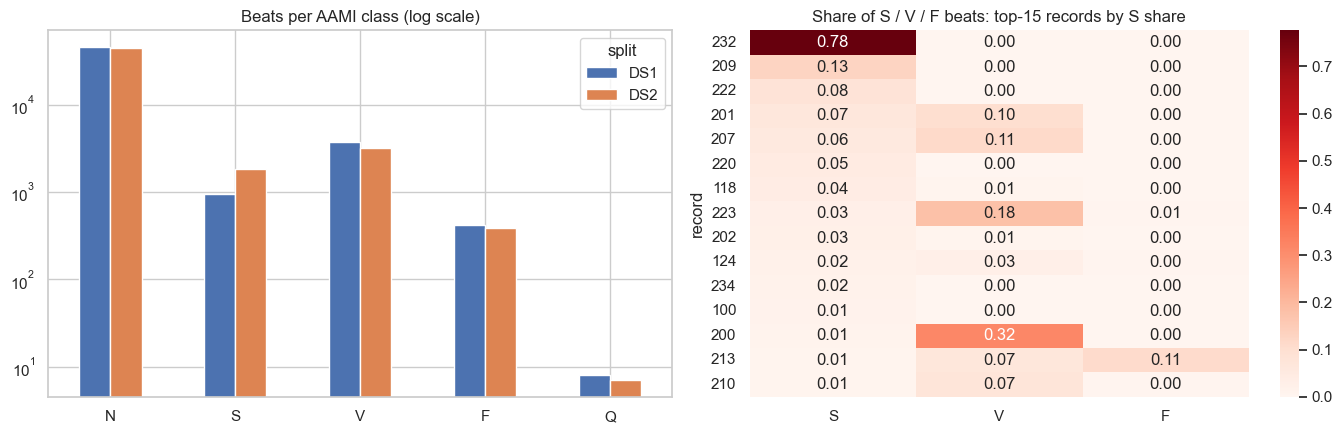

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
overview.groupby('split')[list('NSVFQ')].sum().T.plot.bar(ax=ax[0], logy=True, rot=0, title='Beats per AAMI class (log scale)')
share = overview.set_index('record')[list('SVF')].div(overview.set_index('record').n_beats, axis=0)
sns.heatmap(share.sort_values('S', ascending=False).head(15), annot=True, fmt='.2f', cmap='Reds', ax=ax[1])
ax[1].set_title('Share of S / V / F beats: top-15 records by S share')
plt.tight_layout()
plt.show()

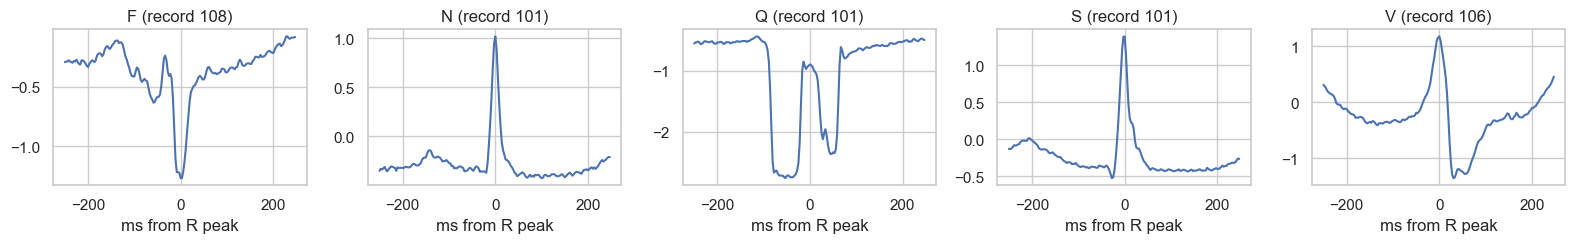

Annotation symbols that are NOT heartbeats (rhythm / quality markers, skipped): [('+', 1173), ('~', 573), ('!', 472), ('"', 437), ('x', 193), ('|', 131), ('[', 6), (']', 6)]


In [ ]:
def collect_examples(ids, half=HALF):
    out = {}
    for rid in ids:
        rec = wfdb.rdrecord(rec_path(rid), channels=[0]); a = wfdb.rdann(rec_path(rid), 'atr')
        sig = rec.p_signal[:, 0]
        for p, s in zip(a.sample, a.symbol):
            c = AAMI.get(s)
            if c and c not in out and half < p < len(sig) - half: out[c] = (rid, sig[p - half:p + half])
        if len(out) == 5: break
    return out

ex = collect_examples(DS1 + DS2)
fig, axes = plt.subplots(1, len(ex), figsize=(3.2 * len(ex), 2.6), sharey=False)
for ax, (c, (rid, seg)) in zip(np.atleast_1d(axes), sorted(ex.items())):
    ax.plot(np.arange(-HALF, HALF) / FS * 1000, seg)
    ax.set_title(f'{c} (record {rid})')
    ax.set_xlabel('ms from R peak')
plt.tight_layout()
plt.show()

nonbeat = Counter()
for rid in DS1 + DS2:
    nonbeat.update(s for s in wfdb.rdann(rec_path(rid), 'atr').symbol if s not in AAMI)
print('Annotation symbols that are NOT heartbeats (rhythm / quality markers, skipped):', nonbeat.most_common())

## 2. Experiment 1: heart-rate window classification

**Question.** Could we simply classify 10-beat windows as bradycardia (< 60 bpm), normal (60-100) or tachycardia (> 100)? MIT-BIH has no such labels, so we derived them from the mean heart rate of each window.

**Hypothesis to test.** If the label is computed from mean RR, any model that sees mean RR (or min/max RR) will look perfect without learning anything. We test with and without those features.

In [ ]:
BEATSYM = set("NLRBAaJSVrFejnE/fQ?")           # real beat symbols only

def make_windows(rid, win=10, step=5):
    rec = wfdb.rdrecord(rec_path(rid), channels=[0]); ann = wfdb.rdann(rec_path(rid), 'atr')
    sig, fs = rec.p_signal[:, 0], rec.fs
    peaks = np.array([s for s, sym in zip(ann.sample, ann.symbol) if sym in BEATSYM])
    rows = []
    for a in range(0, len(peaks) - win, step):
        p = peaks[a:a + win + 1]; rr = np.diff(p) / fs; amp = sig[p]; hr = 60 / rr.mean()
        rows.append(dict(record=rid, hr=hr, rr_mean=rr.mean(), rr_std=rr.std(), rr_min=rr.min(), rr_max=rr.max(),
                         rmssd=np.sqrt(np.mean(np.diff(rr) ** 2)), amp_mean=amp.mean(), amp_std=amp.std(),
                         label=0 if hr < 60 else (1 if hr <= 100 else 2)))          # 0 brady, 1 normal, 2 tachy
    return rows

hr_train = pd.DataFrame([r for i in DS1 for r in make_windows(i)])
hr_test = pd.DataFrame([r for i in DS2 for r in make_windows(i)])
print(hr_train.label.value_counts().to_dict(), hr_test.label.value_counts().to_dict())

def run_hr(feature_list, tag):
    for name, m in [('LR', make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=2000))),
                    ('RF', RandomForestClassifier(200, class_weight='balanced', random_state=0, n_jobs=-1))]:
        m.fit(hr_train[feature_list], hr_train.label)
        p = m.predict(hr_test[feature_list])
        print(f'{tag:<28s} {name}: accuracy={np.mean(p == hr_test.label):.3f}  macro-F1={f1_score(hr_test.label, p, average="macro"):.3f}')

run_hr(['rr_mean', 'rr_std', 'rr_min', 'rr_max', 'rmssd', 'amp_mean', 'amp_std'], 'with HR-defining features')
run_hr(['rr_std', 'rmssd', 'amp_mean', 'amp_std'], 'without them (honest)')

{1: 7633, 2: 1407, 0: 1128} {1: 7000, 0: 1541, 2: 1366}
with HR-defining features    LR: accuracy=0.970  macro-F1=0.960
with HR-defining features    RF: accuracy=0.999  macro-F1=0.999
without them (honest)        LR: accuracy=0.527  macro-F1=0.450
without them (honest)        RF: accuracy=0.629  macro-F1=0.319


In [ ]:
BEATSYM = set("NLRBAaJSVrFejnE/fQ?")           # real beat symbols only

def make_windows(rid, win=10, step=5):
    rec = wfdb.rdrecord(rec_path(rid), channels=[0]); ann = wfdb.rdann(rec_path(rid), 'atr')
    sig, fs = rec.p_signal[:, 0], rec.fs
    peaks = np.array([s for s, sym in zip(ann.sample, ann.symbol) if sym in BEATSYM])
    rows = []
    for a in range(0, len(peaks) - win, step):
        p = peaks[a:a + win + 1]; rr = np.diff(p) / fs; amp = sig[p]; hr = 60 / rr.mean()
        rows.append(dict(record=rid, hr=hr, rr_mean=rr.mean(), rr_std=rr.std(), rr_min=rr.min(), rr_max=rr.max(),
                         rmssd=np.sqrt(np.mean(np.diff(rr) ** 2)), amp_mean=amp.mean(), amp_std=amp.std(),
                         label=0 if hr < 60 else (1 if hr <= 100 else 2)))          # 0 brady, 1 normal, 2 tachy
    return rows

hr_train = pd.DataFrame([r for i in DS1 for r in make_windows(i)])
hr_test = pd.DataFrame([r for i in DS2 for r in make_windows(i)])
print(hr_train.label.value_counts().to_dict(), hr_test.label.value_counts().to_dict())

def run_hr(feature_list, tag):
    for name, m in [('LR', make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=2000))),
                    ('RF', RandomForestClassifier(200, class_weight='balanced', random_state=0, n_jobs=-1))]:
        m.fit(hr_train[feature_list], hr_train.label)
        p = m.predict(hr_test[feature_list])
        print(f'{tag:<28s} {name}: accuracy={np.mean(p == hr_test.label):.3f}  macro-F1={f1_score(hr_test.label, p, average="macro"):.3f}')

run_hr(['rr_mean', 'rr_std', 'rr_min', 'rr_max', 'rmssd', 'amp_mean', 'amp_std'], 'with HR-defining features')
run_hr(['rr_std', 'rmssd', 'amp_mean', 'amp_std'], 'without them (honest)')

{1: 7633, 2: 1407, 0: 1128} {1: 7000, 0: 1541, 2: 1366}
with HR-defining features    LR: accuracy=0.970  macro-F1=0.960
with HR-defining features    RF: accuracy=0.999  macro-F1=0.999
without them (honest)        LR: accuracy=0.527  macro-F1=0.450
without them (honest)        RF: accuracy=0.629  macro-F1=0.319


## 3. Feature engineering, cached as parquet

Beat-level features are expensive (wavelets, Hermite fits, delineation), so each family is computed once per record and stored as a **parquet** file in `artifacts/`. Every later experiment loads these files and merges them on `(record, sample)`.

| Parquet file | Contents | Source |
|---|---|---|
| `train_beats.parquet`, `test_beats.parquet` | 61 Stage-1 features + `label` for every beat (DS1 / DS2) | Saenz-Cogollo & Agelli (RR, normalised RR, HBF, HOS, DWT, Euclidean distances) |
| `qrs_train.parquet`, `qrs_test.parquet` | 12 QRS and amplitude features at 150 Hz (raw; normalisation is applied after loading) | Appendix A of the same paper |
| `ctx_train.parquet`, `ctx_test.parquet` | 37 patient-relative shape features + 7 RR-context features | our extension |

Beats are read **sequentially per record** and all normalisations use only past beats (the last 32), as a real-time monitor would. The first 32 beats of each record are therefore dropped.

In [ ]:
def cached(name, fn):
    path = ART / name
    if path.exists() and not FORCE_REBUILD:
        return pd.read_parquet(path)
    df = fn(); df.to_parquet(path); return df

# ---------------- Stage 1: RR, normalised RR, HBF, HOS, DWT, Euclidean distances (61 features) ----------------
def eucl(seg, lo, hi, fn):
    i = lo + fn(seg[lo:hi])
    return np.hypot(HALF - i, seg[HALF] - seg[i])               # (samples, amplitude)

def beat_feats(seg):
    f, x, k = {}, np.linspace(-1, 1, len(seg)), 0
    for d in (3, 4, 5):                                          # HBF: Hermite fit, degrees 3,4,5 -> 4+5+6 = 15 coefficients
        for c in hermfit(x, seg, d):
            f[f'hbf_{k}'] = c; k += 1
    for i, part in enumerate(np.array_split(seg, 5)):            # HOS: kurtosis and skewness of 5 equal parts -> 10
        f[f'kurt_{i}'] = kurtosis(part); f[f'skew_{i}'] = skew(part)
    for i, c in enumerate(pywt.wavedec(seg, 'db1', level=3)[0]): # DWT: db1, level-3 approximation -> 23
        f[f'dwt_{i}'] = c
    f['eu_0'] = eucl(seg, 0, 41, np.argmax)                      # Euclidean distances to 4 landmark points -> 4
    f['eu_1'] = eucl(seg, 75, 86, np.argmin)
    f['eu_2'] = eucl(seg, 95, 106, np.argmin)
    f['eu_3'] = eucl(seg, 140, 180, np.argmax)
    return f

def record_feats(rid):
    rec = wfdb.rdrecord(rec_path(rid), channels=[0]); ann = wfdb.rdann(rec_path(rid), 'atr')
    sig = rec.p_signal[:, 0]
    sig = sig - median_filter(median_filter(sig, size=73), size=217)       # baseline removal (200 ms and 600 ms medians)
    keep = [i for i, s in enumerate(ann.symbol) if s in AAMI]
    peaks = ann.sample[keep]; syms = [ann.symbol[i] for i in keep]
    rr = np.diff(peaks) / FS                                                # rr[j]: peaks[j] -> peaks[j+1]
    rows = []
    for k in range(HIST, len(peaks) - 1):
        p = peaks[k]
        if p - HALF < 0 or p + HALF > len(sig): continue
        rr0, rrm1, rrp1 = rr[k - 1], rr[k - 2], rr[k]                       # current, previous, next RR
        hist = rr[k - HIST:k]; avg, sd = hist.mean(), hist.std() + 1e-8     # causal: last 32 RRs
        row = dict(record=rid, sample=p, label=AAMI[syms[k]], rr0=rr0, rr_m1=rrm1, rr_p1=rrp1,
                   rr0_avg=rr0 / avg, rr_m1_avg=rrm1 / avg, rr_p1_avg=rrp1 / avg,
                   rr_m1_rr0=rrm1 / rr0, rr_p1_rr0=rrp1 / rr0, t_rr0=(rr0 - avg) / sd)
        row.update(beat_feats(sig[p - HALF:p + HALF]))
        rows.append(row)
    return pd.DataFrame(rows)

def build(fn, ids):
    return pd.concat(Parallel(n_jobs=-1)(delayed(fn)(i) for i in ids), ignore_index=True)

stage1_tr = cached('train_beats.parquet', lambda: build(record_feats, DS1))
stage1_te = cached('test_beats.parquet', lambda: build(record_feats, DS2))
print(stage1_tr.shape, stage1_te.shape)
print(stage1_tr.label.value_counts().to_dict(), stage1_te.label.value_counts().to_dict())

(50295, 64) (48986, 64)
{'N': 45195, 'V': 3741, 'S': 943, 'F': 408, 'Q': 8} {'N': 43599, 'V': 3180, 'S': 1812, 'F': 388, 'Q': 7}


In [ ]:
def cached(name, fn):
    path = ART / name
    if path.exists() and not FORCE_REBUILD:
        return pd.read_parquet(path)
    df = fn(); df.to_parquet(path); return df

# ---------------- Stage 1: RR, normalised RR, HBF, HOS, DWT, Euclidean distances (61 features) ----------------
def eucl(seg, lo, hi, fn):
    i = lo + fn(seg[lo:hi])
    return np.hypot(HALF - i, seg[HALF] - seg[i])               # (samples, amplitude)

def beat_feats(seg):
    f, x, k = {}, np.linspace(-1, 1, len(seg)), 0
    for d in (3, 4, 5):                                          # HBF: Hermite fit, degrees 3,4,5 -> 4+5+6 = 15 coefficients
        for c in hermfit(x, seg, d):
            f[f'hbf_{k}'] = c; k += 1
    for i, part in enumerate(np.array_split(seg, 5)):            # HOS: kurtosis and skewness of 5 equal parts -> 10
        f[f'kurt_{i}'] = kurtosis(part); f[f'skew_{i}'] = skew(part)
    for i, c in enumerate(pywt.wavedec(seg, 'db1', level=3)[0]): # DWT: db1, level-3 approximation -> 23
        f[f'dwt_{i}'] = c
    f['eu_0'] = eucl(seg, 0, 41, np.argmax)                      # Euclidean distances to 4 landmark points -> 4
    f['eu_1'] = eucl(seg, 75, 86, np.argmin)
    f['eu_2'] = eucl(seg, 95, 106, np.argmin)
    f['eu_3'] = eucl(seg, 140, 180, np.argmax)
    return f

def record_feats(rid):
    rec = wfdb.rdrecord(rec_path(rid), channels=[0]); ann = wfdb.rdann(rec_path(rid), 'atr')
    sig = rec.p_signal[:, 0]
    sig = sig - median_filter(median_filter(sig, size=73), size=217)       # baseline removal (200 ms and 600 ms medians)
    keep = [i for i, s in enumerate(ann.symbol) if s in AAMI]
    peaks = ann.sample[keep]; syms = [ann.symbol[i] for i in keep]
    rr = np.diff(peaks) / FS                                                # rr[j]: peaks[j] -> peaks[j+1]
    rows = []
    for k in range(HIST, len(peaks) - 1):
        p = peaks[k]
        if p - HALF < 0 or p + HALF > len(sig): continue
        rr0, rrm1, rrp1 = rr[k - 1], rr[k - 2], rr[k]                       # current, previous, next RR
        hist = rr[k - HIST:k]; avg, sd = hist.mean(), hist.std() + 1e-8     # causal: last 32 RRs
        row = dict(record=rid, sample=p, label=AAMI[syms[k]], rr0=rr0, rr_m1=rrm1, rr_p1=rrp1,
                   rr0_avg=rr0 / avg, rr_m1_avg=rrm1 / avg, rr_p1_avg=rrp1 / avg,
                   rr_m1_rr0=rrm1 / rr0, rr_p1_rr0=rrp1 / rr0, t_rr0=(rr0 - avg) / sd)
        row.update(beat_feats(sig[p - HALF:p + HALF]))
        rows.append(row)
    return pd.DataFrame(rows)

def build(fn, ids):
    return pd.concat(Parallel(n_jobs=-1)(delayed(fn)(i) for i in ids), ignore_index=True)

stage1_tr = cached('train_beats.parquet', lambda: build(record_feats, DS1))
stage1_te = cached('test_beats.parquet', lambda: build(record_feats, DS2))
print(stage1_tr.shape, stage1_te.shape)
print(stage1_tr.label.value_counts().to_dict(), stage1_te.label.value_counts().to_dict())

(50295, 64) (48986, 64)
{'N': 45195, 'V': 3741, 'S': 943, 'F': 408, 'Q': 8} {'N': 43599, 'V': 3180, 'S': 1812, 'F': 388, 'Q': 7}


In [ ]:
# ---------------- Stage 2: QRS widths and amplitude differences (Appendix A of the paper) ----------------
# Computed on the signal resampled to 150 Hz, window = 56 samples before and 40 after the R annotation.
FS2, PRE, POST, MS = 150, 56, 40, 1000 / 150
RAW = ['QRSw', 'QRSw2', 'QRSw4', 'QSd', 'PQa', 'QRa', 'RSa', 'PRd', 'Ppeak', 'Qpeak', 'Rpeak', 'Speak']

def _walk(s, m, step, thr):
    i = m
    while 0 < i < len(s) - 1 and s[i] >= thr: i += step
    return i

def _extrema(x, m, step):
    d, out, i = np.diff(x), [], m
    while True:
        i += step
        if not (0 < i < len(x) - 1): break
        if d[i - 1] * d[i] < 0: out.append(i)
    return out

def qrs_feats(sig, r):
    if r - PRE < 0 or r + POST > len(sig): return None
    x = sig[r - PRE:r + POST].astype(float); x = x - x.mean()               # baseline = segment mean
    w = np.arange(PRE - 15, PRE + 16)                                       # +-100 ms around the annotation
    m = w[np.argmax(np.abs(x[w]))]; qmax = x[m]
    s = x * (1.0 if qmax > 0 else -1.0)                                     # polarity-adjusted copy
    a2, b2 = _walk(s, m, -1, abs(qmax) / 2), _walk(s, m, 1, abs(qmax) / 2)  # half-height crossings
    a4, b4 = _walk(s, m, -1, abs(qmax) / 4), _walk(s, m, 1, abs(qmax) / 4)  # quarter-height crossings
    R = Q = S = P = 0.0; iq = is_ = ip = None
    back, fwd = _extrema(x, m, -1), _extrema(x, m, 1)
    qs = None
    if qmax > 0:
        R = qmax
        if back and x[back[0]] < 0:
            iq = back[0]; Q = x[iq]
            neg = np.where(x[:iq] >= 0)[0]
            qs = neg[-1] if len(neg) else (back[1] if len(back) > 1 and x[back[1]] >= 0 else 0)
        elif back: qs = back[0]
    else:
        S, is_ = qmax, m
        if back and x[back[0]] > 0: R = x[back[0]]
        if back: qs = back[0]
    qs = 0 if qs is None else qs
    if qmax > 0 and fwd and x[fwd[0]] < 0: is_ = fwd[0]; S = x[is_]
    qe = None
    if is_ is not None:
        pos = np.where(x[is_:] >= 0)[0]
        qe = is_ + pos[0] if len(pos) else None
    if qe is None:
        cand = [i for i in fwd if x[i] >= 0]
        qe = cand[0] if cand else len(x) - 1
    lo, hi = qs - 35, qs - 10                                               # P-wave search window
    if lo - 10 >= 0 and hi > lo:
        j = lo + int(np.argmax(x[lo:hi + 1]))
        if 0 < j < len(x) - 1 and x[j] > x[j - 1] and x[j] >= x[j + 1] and x[j] > 3 * x[lo - 10:lo].std():
            P, ip = x[j], j
    return dict(QRSw=(qe - qs) * MS, QRSw2=(b2 - a2) * MS, QRSw4=(b4 - a4) * MS,
                QSd=((is_ - iq) * MS if (iq is not None and is_ is not None) else 0.0),
                PQa=P - Q, QRa=R - Q, RSa=R - S, PRd=((qs - ip) * MS if ip is not None else 0.0),
                Ppeak=P, Qpeak=Q, Rpeak=R, Speak=S)

def qrs_record(rid):
    rec = wfdb.rdrecord(rec_path(rid), channels=[0]); ann = wfdb.rdann(rec_path(rid), 'atr')
    sig150 = resample_poly(rec.p_signal[:, 0], 5, 12)                       # 360 -> 150 Hz
    keep = [i for i, s in enumerate(ann.symbol) if s in AAMI]
    rows = []
    for p in ann.sample[keep]:
        f = qrs_feats(sig150, int(round(p * 5 / 12)))
        rows.append({'record': rid, 'sample': p, **(f or {c: np.nan for c in RAW})})
    return pd.DataFrame(rows)

qrs_tr_raw = cached('qrs_train.parquet', lambda: build(qrs_record, DS1))
qrs_te_raw = cached('qrs_test.parquet', lambda: build(qrs_record, DS2))

WIDTHS = ['QRSw', 'QRSw2', 'QRSw4', 'QSd', 'PRd']
def clip_renorm(df, cap=200):
    """Cap artefact widths (some beats never fall below half/quarter height inside the window) and
    divide every feature by its mean over the last 32 beats of the same record (patient-relative)."""
    df = df.copy(); df[WIDTHS] = df[WIDTHS].clip(upper=cap)
    for c in RAW:
        mu = df.groupby('record')[c].transform(lambda s: s.rolling(HIST, min_periods=HIST).mean())
        df[c + '_n'] = df[c] / mu.where(mu.abs() > 1e-6, 1e-6)
    return df

qrs_tr, qrs_te = clip_renorm(qrs_tr_raw), clip_renorm(qrs_te_raw)
print(qrs_tr_raw[['QRSw2', 'QRSw4']].describe().round(1).T)

         count  mean   std   min   25%   50%   75%    max
QRSw2  51005.0  37.3  16.9  13.3  26.7  33.3  46.7  520.0
QRSw4  51005.0  48.3  21.8  13.3  33.3  40.0  53.3  526.7


In [ ]:
# ---------------- RR-context and patient-relative shape features (our extension) ----------------
DUP = ['hbf_5', 'hbf_7', 'hbf_9', 'hbf_11', 'hbf_13']          # exact duplicates of other HBF columns (see EDA)

def add_context(df):
    df = df.sort_values(['record', 'sample']).reset_index(drop=True)
    g = df.groupby('record')
    shape = [c for c in df.columns if c.startswith(('hbf_', 'dwt_', 'eu_')) and c not in DUP]
    out = df[['record', 'sample']].copy()
    for c in shape:                                              # (1) value minus mean of the last 32 beats of the record
        mu = g[c].transform(lambda s: s.rolling(32, min_periods=8).mean())
        out[c + '_d'] = (df[c] - mu).fillna(0.0)
    base = g['rr0'].transform(lambda s: s.shift(1).rolling(8, min_periods=4).median())   # patient baseline RR
    out['premat'] = df.rr0 / base                                # prematurity of this beat
    out['comp'] = (df.rr0 + df.rr_p1) / (2 * base)              # ~1: full compensatory pause (V); < 1: S-like
    out['pause_next'] = df.rr_p1 / base
    out['rr_m2_rel'] = g['rr0'].shift(2) / base                  # two beats back
    out['rr_p2_rel'] = g['rr0'].shift(-2) / base                 # one extra future beat
    out['std8_rel'] = g['rr0'].transform(lambda s: s.rolling(8, min_periods=4).std()) / base
    d2 = g['rr0'].transform(lambda s: s.diff() ** 2)
    out['rmssd8_rel'] = np.sqrt(d2.groupby(df.record).transform(lambda s: s.rolling(8, min_periods=4).mean())) / base
    ratio, irr = ['premat', 'comp', 'pause_next', 'rr_m2_rel', 'rr_p2_rel'], ['std8_rel', 'rmssd8_rel']
    out[ratio + irr] = out[ratio + irr].replace([np.inf, -np.inf], np.nan)
    out[ratio] = out[ratio].fillna(1.0); out[irr] = out[irr].fillna(0.0)
    return out

ctx_tr = cached('ctx_train.parquet', lambda: add_context(stage1_tr))
ctx_te = cached('ctx_test.parquet', lambda: add_context(stage1_te))
print(ctx_tr.shape, ctx_te.shape)

(50295, 46) (48986, 46)


### Assembling the model tables

Feature sets used throughout (names match the experiments below):

* `S1` (56): Stage-1 features without the 5 duplicate HBF columns
* `QRS` (24): 12 QRS / amplitude features and their 12 patient-relative versions
* `feats = S1 + QRS` (80): the paper's 85 minus the 5 duplicates
* `SHAPE_D` (37) and `CTX` (7): our extension features, `feats2` (124) = everything

`train1` holds **N, S, V only** (the paper trains on these three); `test1` keeps **every** DS2 beat, including F and Q, which count as errors in the evaluation, as in the paper.

In [ ]:
S1_ALL = [c for c in stage1_tr.columns if c not in ('record', 'sample', 'label')]
S1 = [c for c in S1_ALL if c not in DUP]
QRS = RAW + [c + '_n' for c in RAW]
SHAPE_D = [c for c in ctx_tr.columns if c.endswith('_d')]
CTX = ['premat', 'comp', 'pause_next', 'rr_m2_rel', 'rr_p2_rel', 'std8_rel', 'rmssd8_rel']
feats, feats2 = S1 + QRS, S1 + QRS + SHAPE_D + CTX
assert (len(S1), len(QRS), len(SHAPE_D), len(CTX)) == (56, 24, 37, 7), (len(S1), len(QRS), len(SHAPE_D), len(CTX))

def assemble(stage1, qrs, ctx):
    return (stage1.merge(qrs, on=['record', 'sample'], how='left')
                  .merge(ctx, on=['record', 'sample'], how='left')
                  .drop_duplicates(['record', 'sample']).reset_index(drop=True))

full_tr, full_te = assemble(stage1_tr, qrs_tr, ctx_tr), assemble(stage1_te, qrs_te, ctx_te)
train1 = full_tr[full_tr.label.isin(['N', 'S', 'V'])].dropna(subset=feats2).reset_index(drop=True)
test1 = full_te.dropna(subset=feats2).reset_index(drop=True)
print(len(feats), len(feats2), '| train1', train1.shape, '| test1', test1.shape)
print('train1', train1.label.value_counts().to_dict()); print('test1 ', test1.label.value_counts().to_dict())
print('duplicate keys:', train1.duplicated(['record', 'sample']).sum(), test1.duplicated(['record', 'sample']).sum())

80 124 | train1 (49872, 132) | test1 (48986, 132)
train1 {'N': 45188, 'V': 3741, 'S': 943}
test1  {'N': 43599, 'V': 3180, 'S': 1812, 'F': 388, 'Q': 7}
duplicate keys: 0 0


4. Feature-level EDA
Each check below was added because the previous model run disagreed with the paper, or because it exposed a data problem. Findings and the fixes they triggered are listed after each block.

4.1 Data-quality audit: NaN, duplicate columns, annotation gaps, width artifacts

In [ ]:
audit = pd.DataFrame({'NaN (train)': full_tr[feats2].isna().sum(), 'NaN (test)': full_te[feats2].isna().sum()})
print('Columns with missing values:'); display(audit[audit.sum(axis=1) > 0])

dup_cols = stage1_tr[S1_ALL].round(6).T.duplicated()
print('Exact duplicate columns in Stage 1:', dup_cols[dup_cols].index.tolist())

for name, df in (('train', full_tr), ('test', full_te)):
    gap = df[['rr0', 'rr_m1', 'rr_p1']].max(axis=1) > 3
    print(f'{name}: {gap.sum()} beats adjacent to an RR gap > 3 s, records {sorted(df[gap].record.unique())}')
print('Max RR (s):', round(full_tr.rr0.max(), 1), '| QRS widths > 150 ms (artefacts):',
      int((qrs_tr_raw.QRSw2 > 150).sum()), 'of', len(qrs_tr_raw))

Columns with missing values:


,NaN (train),NaN (test)
kurt_0,4,0
skew_0,4,0
kurt_1,4,0
skew_1,4,0
kurt_2,2,0
skew_2,2,0
kurt_3,1,0
skew_3,1,0
kurt_4,4,0
skew_4,4,0


Exact duplicate columns in Stage 1: ['hbf_5', 'hbf_7', 'hbf_9', 'hbf_11', 'hbf_13']
train: 25 beats adjacent to an RR gap > 3 s, records [np.int64(201), np.int64(207), np.int64(208)]
test: 96 beats adjacent to an RR gap > 3 s, records [np.int64(219), np.int64(232)]
Max RR (s): 100.0 | QRS widths > 150 ms (artefacts): 73 of 51021


4.2 Class balance and patient concentration (the key structural finding)

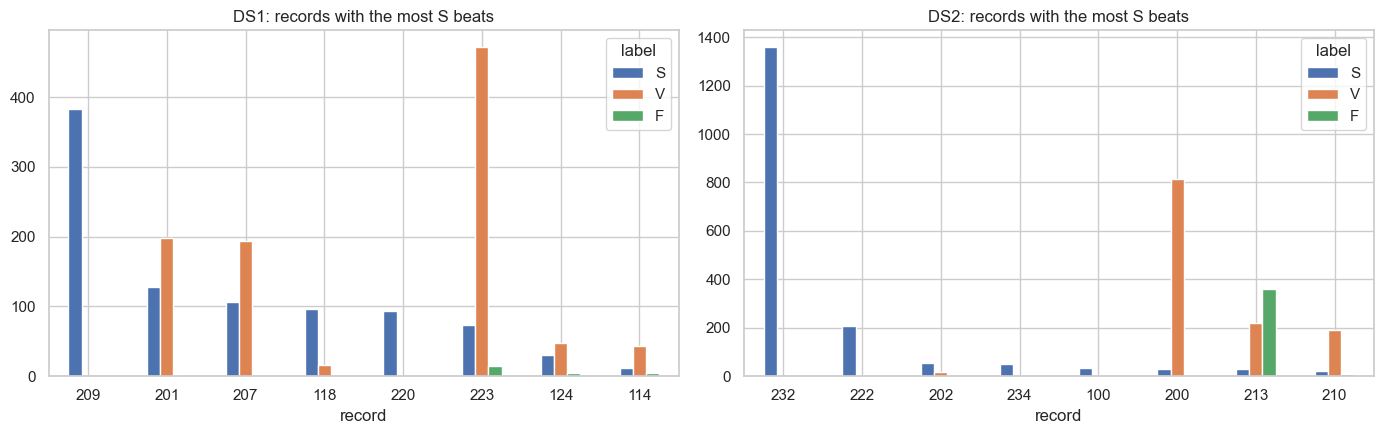

DS1 S: top record 209 holds 41% of 943 beats
DS1 F: top record 208 holds 90% of 408 beats
DS2 S: top record 232 holds 75% of 1812 beats
DS2 F: top record 213 holds 93% of 388 beats


In [ ]:
ct_tr = pd.crosstab(full_tr.record, full_tr.label); ct_te = pd.crosstab(full_te.record, full_te.label)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, (name, ct) in zip(ax, (('DS1', ct_tr), ('DS2', ct_te))):
    top = ct.sort_values('S', ascending=False).head(8)[[c for c in ['S', 'V', 'F'] if c in ct.columns]]
    top.plot.bar(ax=a, rot=0, title=f'{name}: records with the most S beats'); a.set_xlabel('record')
plt.tight_layout()
plt.show()

for name, ct in (('DS1', ct_tr), ('DS2', ct_te)):
    for cls in [c for c in ['S', 'F'] if c in ct.columns]:
        tot = ct[cls].sum()
        if tot: print(f'{name} {cls}: top record {ct[cls].idxmax()} holds {ct[cls].max() / tot:.0%} of {tot} beats')

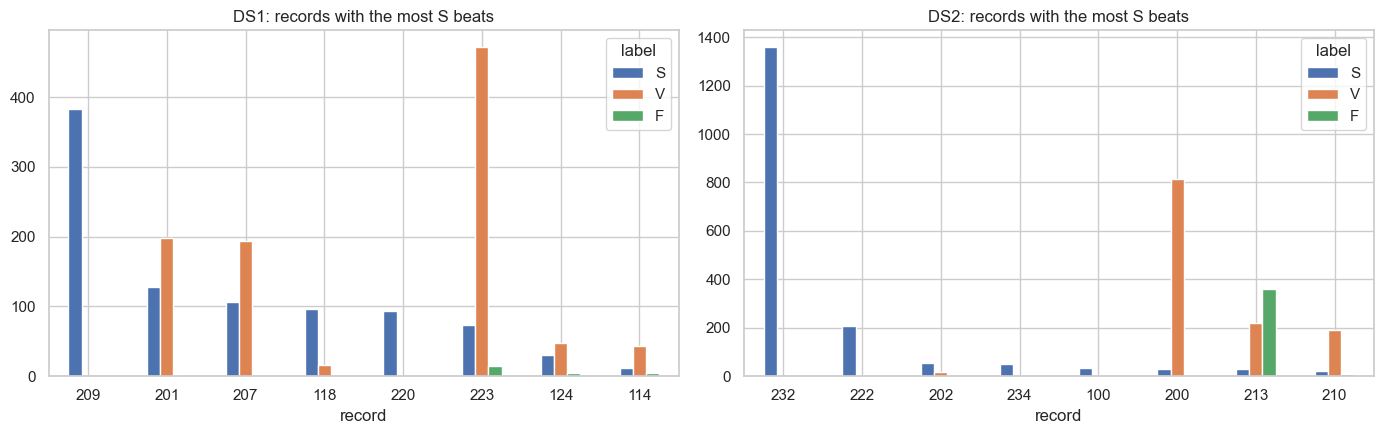

DS1 S: top record 209 holds 41% of 943 beats
DS1 F: top record 208 holds 90% of 408 beats
DS2 S: top record 232 holds 75% of 1812 beats
DS2 F: top record 213 holds 93% of 388 beats


In [ ]:
ct_tr = pd.crosstab(full_tr.record, full_tr.label); ct_te = pd.crosstab(full_te.record, full_te.label)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, (name, ct) in zip(ax, (('DS1', ct_tr), ('DS2', ct_te))):
    top = ct.sort_values('S', ascending=False).head(8)[[c for c in ['S', 'V', 'F'] if c in ct.columns]]
    top.plot.bar(ax=a, rot=0, title=f'{name}: records with the most S beats'); a.set_xlabel('record')
plt.tight_layout()
plt.show()

for name, ct in (('DS1', ct_tr), ('DS2', ct_te)):
    for cls in [c for c in ['S', 'F'] if c in ct.columns]:
        tot = ct[cls].sum()
        if tot: print(f'{name} {cls}: top record {ct[cls].idxmax()} holds {ct[cls].max() / tot:.0%} of {tot} beats')

4.3 Automated profiling (ydata-profiling)

In [ ]:
if RUN_PROFILING:
    from ydata_profiling import ProfileReport
    sample = train1[feats + ['label']].sample(min(10000, len(train1)), random_state=0)
    ProfileReport(sample, minimal=True, title='DS1 features (minimal)').to_file(ART / 'eda_minimal.html')
    ProfileReport(sample, title='DS1 features (full, 10k sample)', interactions=None).to_file(ART / 'eda_full.html')
    print('Reports written to', ART)
else:
    print('Profiling skipped')

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|█████████████████████████████████████████████████████████████████████████████████| 81/81 [00:00<00:00, 109.14it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|█████████████████████████████████████████████████████████████████████████████████| 81/81 [00:00<00:00, 101.44it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Reports written to artifacts


4.4 Redundancy, mutual-information ranking, class-conditional distributions

8 feature pairs with |r| >= 0.99, e.g. [('hbf_4', 'hbf_6', np.float64(0.993)), ('hbf_4', 'hbf_8', np.float64(0.992)), ('hbf_6', 'hbf_8', np.float64(0.998)), ('hbf_10', 'hbf_12', np.float64(0.998)), ('hbf_10', 'hbf_14', np.float64(0.994)), ('hbf_12', 'hbf_14', np.float64(0.998))]


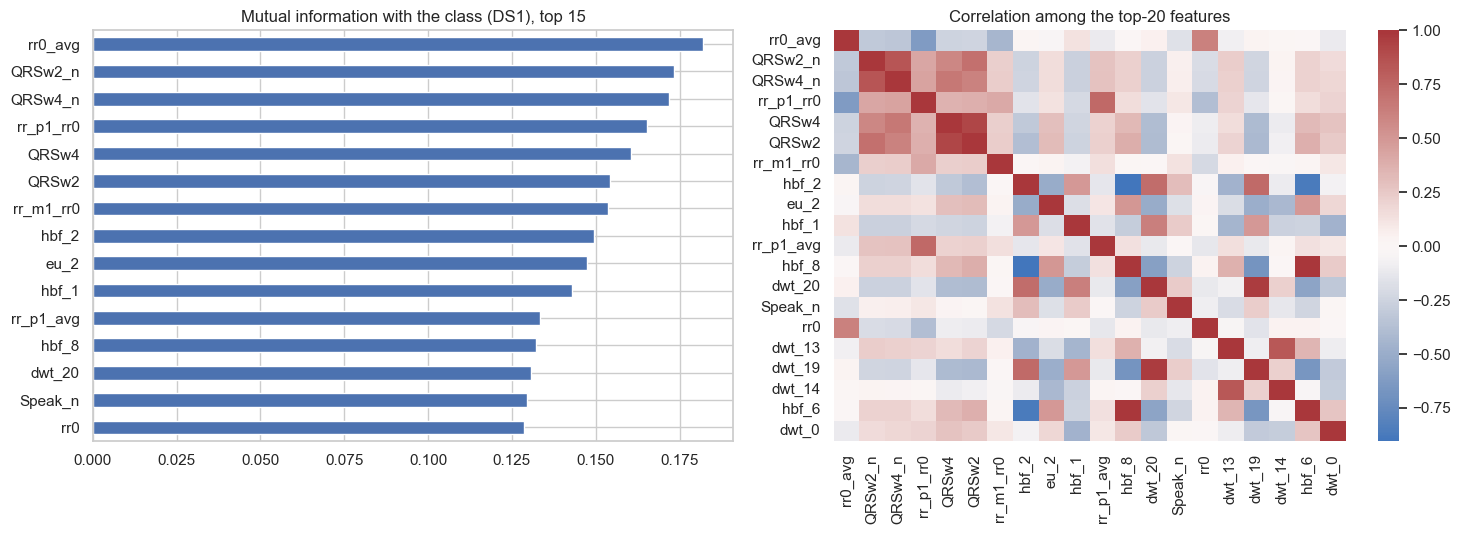

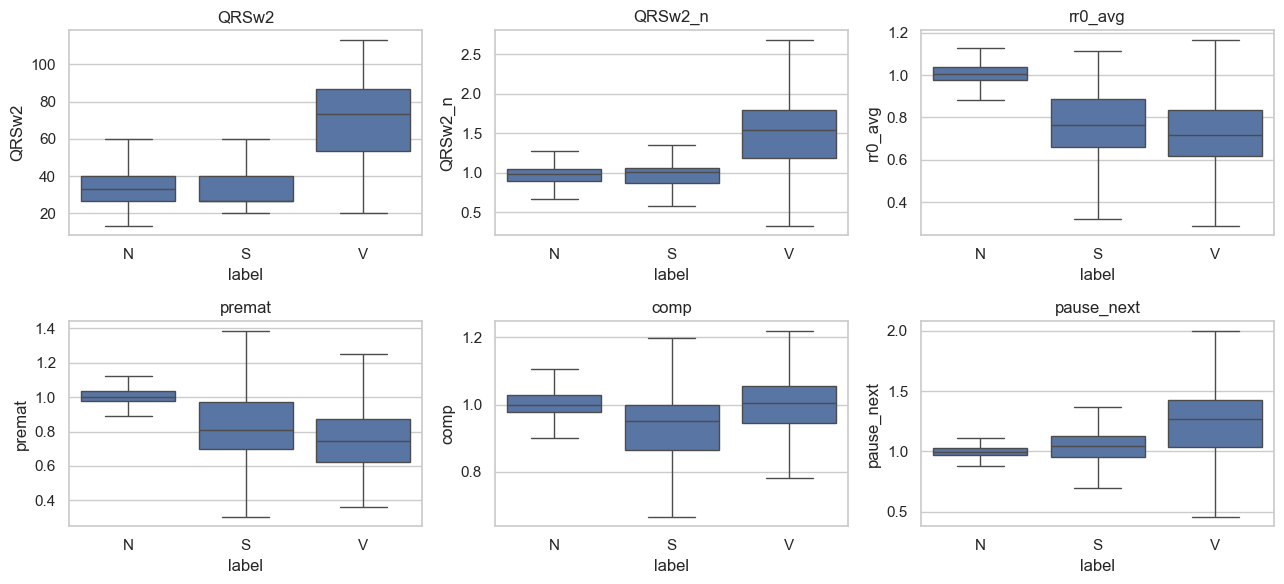

,QRSw2,QRSw4,QRSw2_n,QRSw4_n,premat,comp,pause_next
label,,,,,,,
N,33.333,40.000,0.990,0.982,1.004,1.000,0.998
S,26.667,40.000,1.016,1.003,0.810,0.952,1.048
V,73.333,93.333,1.542,1.514,0.745,1.005,1.271


In [ ]:
ranked = pd.Series(mutual_info_classif(train1[feats], train1.label, random_state=0), index=feats).sort_values(ascending=False)

C = train1[feats].sample(min(20000, len(train1)), random_state=0).corr()
pairs = [(a, b, round(C.loc[a, b], 3)) for i, a in enumerate(C.columns) for b in C.columns[i + 1:] if abs(C.loc[a, b]) >= 0.99]
print(len(pairs), 'feature pairs with |r| >= 0.99, e.g.', pairs[:6])

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
ranked.head(15)[::-1].plot.barh(ax=ax[0], title='Mutual information with the class (DS1), top 15')
topc = list(ranked.index[:20])
sns.heatmap(C.loc[topc, topc], cmap='vlag', center=0, ax=ax[1], xticklabels=True, yticklabels=True)
ax[1].set_title('Correlation among the top-20 features')
plt.tight_layout()
plt.show()

show = ['QRSw2', 'QRSw2_n', 'rr0_avg', 'premat', 'comp', 'pause_next']
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for a, c in zip(axes.ravel(), show):
    sns.boxplot(data=train1, x='label', y=c, order=['N', 'S', 'V'], showfliers=False, ax=a)
    a.set_title(c)
plt.tight_layout()
plt.show()
display(train1.groupby('label')[['QRSw2', 'QRSw4', 'QRSw2_n', 'QRSw4_n', 'premat', 'comp', 'pause_next']].median().round(3))

4.5 Patient structure: do beats cluster by patient or by class?

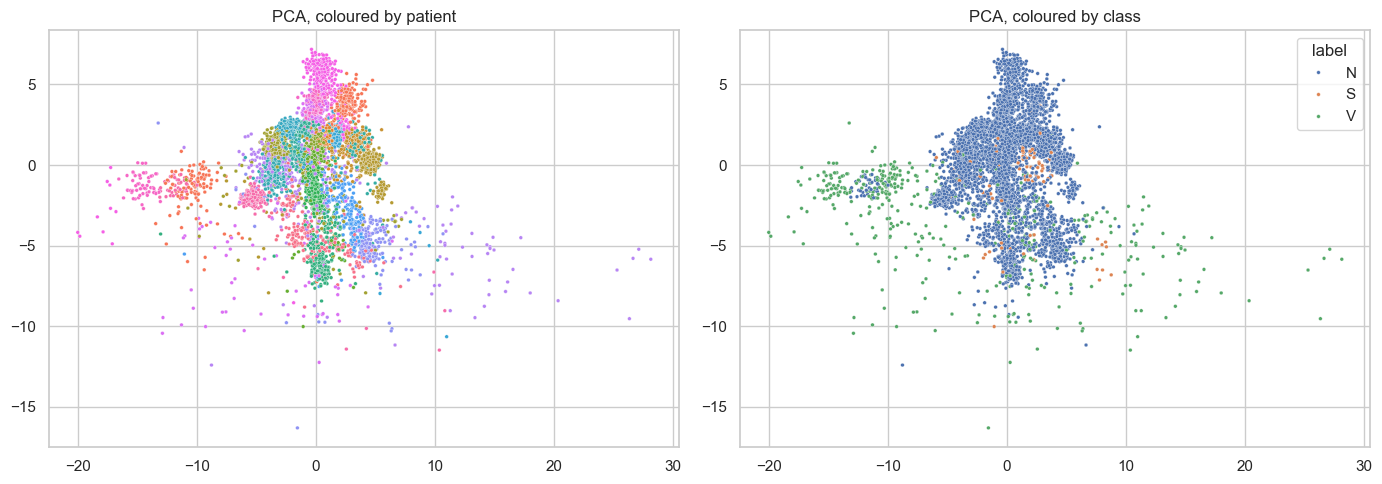

In [ ]:
samp = train1.sample(min(6000, len(train1)), random_state=0)
Z = PCA(2, random_state=0).fit_transform(StandardScaler().fit_transform(samp[S1 + QRS]))
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=samp.record.astype(str), s=7, ax=ax[0], legend=False)
ax[0].set_title('PCA, coloured by patient')
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=samp.label, hue_order=['N', 'S', 'V'], s=7, ax=ax[1])
ax[1].set_title('PCA, coloured by class')
plt.tight_layout()
plt.show()

**Interpretation.** If beats form patient islands rather than class regions, a model trained with random beat splits would memorise patients and over-report accuracy. This is why every experiment uses leave-one-patient-out or the fixed DS1/DS2 patient split.

### 4.6 DS1 vs DS2 distribution shift
Per-feature Kolmogorov-Smirnov distance and *adversarial validation*: a classifier that tries to tell DS1 beats from DS2 beats on unseen patients. AUC near 0.5 means no systematic shift between the splits beyond patient identity.

In [ ]:
n = min(8000, len(train1), int((test1.label.isin(['N', 'S', 'V'])).sum()))
tr_s = train1[feats].sample(n, random_state=0)
te_s = test1[test1.label.isin(['N', 'S', 'V'])][feats].sample(n, random_state=0)
ks = pd.Series({c: ks_2samp(tr_s[c], te_s[c]).statistic for c in feats}).sort_values(ascending=False)
print('Largest KS distances DS1 vs DS2:'); print(ks.head(8).round(3))

Xa, ya_ = pd.concat([tr_s, te_s]), np.r_[np.zeros(n), np.ones(n)]
ga_ = np.r_[train1.loc[tr_s.index, 'record'].values, test1.loc[te_s.index, 'record'].values]
recs_tr, recs_te = np.unique(train1.record), np.unique(test1.record)
k = min(5, len(recs_tr), len(recs_te))
fold_of = {r: i % k for i, r in enumerate(recs_tr)}; fold_of.update({r: i % k for i, r in enumerate(recs_te)})
folds = np.array([fold_of[r] for r in ga_])
pa = cross_val_predict(RandomForestClassifier(100, n_jobs=-1, random_state=0), Xa, ya_, cv=PredefinedSplit(folds),
                       method='predict_proba')[:, 1]
print('Adversarial-validation AUC (unseen patients):', round(roc_auc_score(ya_, pa), 3))

Largest KS distances DS1 vs DS2:
Speak     0.316
skew_2    0.299
dwt_12    0.210
hbf_14    0.163
dwt_0     0.158
PQa       0.156
dwt_5     0.154
hbf_12    0.153
dtype: float64
Adversarial-validation AUC (unseen patients): 0.47


## 5. Evaluation protocol and helpers

* **Split.** Fixed inter-patient DS1 (train) / DS2 (test); no patient appears in both.
* **Model selection on DS1 only**, with *leave-one-patient-out* (LOPO) cross-validation: each of the 22 DS1 records is held out in turn. DS2 is looked at only for a small set of **pre-declared** models, once each, never for tuning.
* **Training classes.** N, S, V only. F and Q beats stay in the test set and count as errors for the class they get predicted as (the paper's protocol).
* **Metrics.** Per-class F1 for N, S, V and their mean ("macro N/S/V"); accuracy is dominated by N and is reported only for comparison with the paper. For S we also report recall on record 232 (S-dominant) and on all other records.

In [ ]:
lab = {'N': 0, 'S': 1, 'V': 2}; inv = {v: k for k, v in lab.items()}
logo = LeaveOneGroupOut()
ytr, grp = train1.label.map(lab).values, train1.record.values

MODELS = {
    'RF':  lambda: RandomForestClassifier(n_estimators=RF_TREES, n_jobs=-1, random_state=0),
    'ET':  lambda: ExtraTreesClassifier(n_estimators=5 * RF_TREES, n_jobs=-1, random_state=0),
    # regularised boosters (used for the final DS2 table and in the GA pool)
    'XGB': lambda: xgb.XGBClassifier(n_estimators=BOOST_TREES, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                     min_child_weight=5, tree_method='hist', n_jobs=-1, random_state=0),
    'LGB': lambda: lgb.LGBMClassifier(n_estimators=BOOST_TREES, num_leaves=15, learning_rate=0.05, min_child_samples=30, subsample=0.8,
                                      colsample_bytree=0.8, n_jobs=-1, random_state=0, verbose=-1),
    # library defaults (used in the first booster comparison, Experiment 5)
    'XGB_def': lambda: xgb.XGBClassifier(random_state=0, n_jobs=-1),
    'LGB_def': lambda: lgb.LGBMClassifier(random_state=0, n_jobs=-1, verbose=-1)}

lopo_log = {}                                                    # tag -> DS1 LOPO scores, reused in the final table

def lopo_pred(make, cols):
    return cross_val_predict(make(), train1[cols], ytr, groups=grp, cv=logo)

def lopo(make, cols, tag=None):
    p = lopo_pred(make, cols)
    f = f1_score(ytr, p, labels=[0, 1, 2], average=None, zero_division=0)
    res = dict(acc=(p == ytr).mean(), macroF1_NSV=f.mean(), F1_N=f[0], F1_S=f[1], F1_V=f[2])
    if tag: lopo_log[tag] = res
    return res

def sweep(ranked_list, n_range=SWEEP, make=MODELS['RF']):
    return pd.DataFrame([dict(n_feats=n, **lopo(make, list(ranked_list.index[:n]))) for n in n_range]).round(4)

def eval_ds2(make, cols, name, verbose=True):
    """Fit on DS1 (N/S/V), predict every DS2 beat (F and Q included). Returns a result row and the predictions."""
    m = make().fit(train1[cols], ytr)
    pred = pd.Series(m.predict(test1[cols])).map(inv).values
    f = f1_score(test1.label, pred, labels=['N', 'S', 'V'], average=None, zero_division=0)
    s = (test1.label == 'S').values; r = (test1.record == REC_S_HEAVY).values
    row = dict(model=name, acc=(pred == test1.label.values).mean(), F1_N=f[0], F1_S=f[1], F1_V=f[2], macro_NSV=f.mean(),
               S_rec_heavy=(pred[s & r] == 'S').mean() if (s & r).any() else np.nan,
               S_rec_other=(pred[s & ~r] == 'S').mean() if (s & ~r).any() else np.nan)
    if verbose:
        print('==', name)
        print(classification_report(test1.label, pred, labels=['N', 'S', 'V'], digits=4, zero_division=0))
        display(pd.crosstab(test1.label, pred))
        print(f'S recall | record {REC_S_HEAVY}: {row["S_rec_heavy"]:.3f} | other records: {row["S_rec_other"]:.3f}')
    return row, pred

## 6. Experiment 2: Stage-1 features only

**Question.** Do the 61 shape and RR features (no QRS widths) classify AAMI beats under the inter-patient protocol?
**Method.** Rank features by mutual information on DS1, sweep the number of top features with LOPO, then evaluate once on DS2 and inspect the errors.

In [ ]:
lr_make = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
display(pd.DataFrame({'LR (scaled), 56 Stage-1 features': lopo(lr_make, S1),
                      'RF, 56 Stage-1 features': lopo(MODELS['RF'], S1)}).T.round(4))

,acc,macroF1_NSV,F1_N,F1_S,F1_V
"LR (scaled), 56 Stage-1 features",0.9000,0.5255,0.9558,0.1211,0.4996
"RF, 56 Stage-1 features",0.9199,0.6133,0.9595,0.2375,0.6430


In [ ]:
ranked_s1 = pd.Series(mutual_info_classif(train1[S1], train1.label, random_state=0), index=S1).sort_values(ascending=False)
print(ranked_s1.head(10).round(4).to_dict())
display(sweep(ranked_s1))
top6_s1 = list(ranked_s1.index[:6])
row_s1, pred_s1 = eval_ds2(MODELS['RF'], top6_s1, 'RF, Stage-1 top-6')

{'rr0_avg': 0.1818, 'rr_p1_rr0': 0.1644, 'rr_m1_rr0': 0.1534, 'hbf_2': 0.1496, 'eu_2': 0.147, 'hbf_1': 0.1428, 'rr_p1_avg': 0.1335, 'hbf_8': 0.1321, 'dwt_20': 0.1314, 'rr0': 0.1301}


,n_feats,acc,macroF1_NSV,F1_N,F1_S,F1_V
0,1,0.9062,0.4998,0.9591,0.0664,0.4739
1,2,0.9334,0.5696,0.9713,0.1033,0.6341
2,3,0.9363,0.5960,0.9716,0.1786,0.6378
3,4,0.9287,0.5681,0.9687,0.0959,0.6397
4,5,0.9258,0.5667,0.9668,0.1053,0.6282
5,6,0.9331,0.5906,0.9688,0.1248,0.6781
6,7,0.9331,0.5899,0.9688,0.1245,0.6764
7,8,0.9308,0.5915,0.9670,0.1352,0.6723
8,9,0.9317,0.5970,0.9678,0.1442,0.6790
9,10,0.9164,0.5625,0.9595,0.1050,0.6229


== RF, Stage-1 top-6
              precision    recall  f1-score   support

           N     0.9691    0.9041    0.9354     43599
           S     0.7589    0.5265    0.6217      1812
           V     0.4056    0.9000    0.5592      3180

   micro avg     0.8825    0.8897    0.8861     48591
   macro avg     0.7112    0.7768    0.7055     48591
weighted avg     0.9244    0.8897    0.8991     48591



col_0,N,S,V
label,,,
F,317,2,69
N,39416,290,3893
Q,3,0,4
S,630,954,228
V,307,11,2862


S recall | record 232: 0.597 | other records: 0.314


In [ ]:
fp = (pred_s1 == 'V') & (test1.label.values == 'N')
print('False-V records:'); print(test1[fp].record.value_counts().head(6).to_dict())
for rid in REC_BBB:
    a = wfdb.rdann(rec_path(rid), 'atr'); print('record', rid, dict(Counter(s for s in a.symbol if s in AAMI)))
m = ~test1.record.isin(REC_BBB).values
print('--- same predictions, records', REC_BBB, 'excluded (sensitivity analysis only) ---')
print(classification_report(test1.label[m], pred_s1[m], labels=['N', 'S', 'V'], digits=3, zero_division=0))

False-V records:
{214: 1797, 219: 1666, 233: 246, 105: 55, 222: 55, 213: 32}
record 214 {'L': 2003, 'V': 256, 'Q': 2, 'F': 1}
record 219 {'N': 2082, 'V': 64, 'F': 1, 'A': 7}
--- same predictions, records (214, 219) excluded (sensitivity analysis only) ---
              precision    recall  f1-score   support

           N      0.970     0.983     0.977     39578
           S      0.801     0.528     0.636      1805
           V      0.784     0.914     0.844      2862

   micro avg      0.952     0.960     0.956     44245
   macro avg      0.852     0.808     0.819     44245
weighted avg      0.951     0.960     0.954     44245



## 7. Experiment 3: protocol corrections and Stage-2 QRS features (the replication)

Reading Appendix A and the results tables of the paper revealed three differences from what we had been doing:

1. **DS2 must include record 222** (22 records). We had 21, so DS2 had 1,603 S beats instead of about 1,812 (the paper has 1,837).
2. **Train on N, S, V only.** F and Q are excluded from training but included in the evaluation as errors.
3. **QRS widths and amplitude differences** (24 features) computed at 150 Hz, with patient-relative versions (divided by the mean of the last 32 beats).

These corrections are already built into `train1` / `test1` above.

**Questions.** Do the new features enter the MI ranking at the top, as in the paper's Table 2 (`QRSw2_n`, `QRSw4_n`, `RR0/avgRR`, `RR+1/RR0`, `QRSw2`, HBF d4 c1, HBF d4 c2, `QRSw4`, HBF d4 c0, `RR-1/RR0`)? Do they fix the false V from records 214 and 219? Do we reproduce the paper's DS2 scores with its top-6 features and 40 trees?

In [ ]:
print('MI top 10:', ranked.head(10).round(4).to_dict())
res_sweep = sweep(ranked); display(res_sweep)
base6 = list(ranked.index[:6])
row_rep, pred_rep = eval_ds2(MODELS['RF'], base6, 'RF paper top-6 (replication)')
lopo_log['RF paper top-6 (replication)'] = lopo(MODELS['RF'], base6)

MI top 10: {'rr0_avg': 0.1819, 'QRSw2_n': 0.1733, 'QRSw4_n': 0.1718, 'rr_p1_rr0': 0.1653, 'QRSw4': 0.1605, 'QRSw2': 0.1542, 'rr_m1_rr0': 0.1537, 'hbf_2': 0.1496, 'eu_2': 0.1475, 'hbf_1': 0.1428}


,n_feats,acc,macroF1_NSV,F1_N,F1_S,F1_V
0,1,0.9062,0.4998,0.9591,0.0664,0.4739
1,2,0.9451,0.6102,0.9752,0.0931,0.7623
2,3,0.9510,0.6246,0.9777,0.1049,0.7910
3,4,0.9552,0.6559,0.9796,0.1793,0.8087
4,5,0.9561,0.7053,0.9786,0.3281,0.8094
5,6,0.9573,0.7319,0.9790,0.4097,0.8072
6,7,0.9617,0.7239,0.9811,0.3526,0.8381
7,8,0.9447,0.6768,0.9728,0.3162,0.7415
8,9,0.9405,0.6636,0.9709,0.3042,0.7158
9,10,0.9392,0.6468,0.9697,0.2465,0.7243


== RF paper top-6 (replication)
              precision    recall  f1-score   support

           N     0.9768    0.9768    0.9768     43599
           S     0.6096    0.7936    0.6895      1812
           V     0.9273    0.8830    0.9046      3180

   micro avg     0.9560    0.9638    0.9599     48591
   macro avg     0.8379    0.8845    0.8570     48591
weighted avg     0.9599    0.9638    0.9614     48591



col_0,N,S,V
label,,,
F,365,0,23
N,42587,859,153
Q,5,0,2
S,332,1438,42
V,310,62,2808


S recall | record 232: 0.858 | other records: 0.600


In [ ]:
r = test1[test1.record == REC_BBB[0]]
display(r.groupby('label')[['QRSw2', 'QRSw2_n', 'QRSw4_n']].median().round(3))
fp = (pred_rep == 'V') & (test1.label.values == 'N')
print('False-V by record after adding QRS features:', test1[fp].record.value_counts().head(5).to_dict())

,QRSw2,QRSw2_n,QRSw4_n
label,,,
F,40.000,0.980,1.123
N,40.000,0.955,0.957
Q,66.667,1.523,1.373
V,60.000,1.326,1.250


False-V by record after adding QRS features: {202: 50, 219: 31, 105: 27, 111: 17, 222: 8}


## 8. Experiment 4: extra features (our extension)

Two ideas, both motivated by the earlier error analysis:

* **RR context** (7 features): prematurity of the beat, compensatory-pause ratio, next pause, RR two back / two ahead, short-window RR irregularity, all relative to the patient's recent baseline (median of the previous 8 RRs). Physiologically, V beats are premature with a full compensatory pause and S beats are premature with a shorter one.
* **Patient-relative shape** (`*_d`, 37 features): HBF / DWT / Euclidean features minus their mean over the last 32 beats of the record. Motivation: normalisation is what fixed record 214, so apply it to shape as well.

**Method.** Add each group to the paper's top-6 and compare under LOPO on DS1 (selection on DS1 only).

In [ ]:
ranked2 = pd.Series(mutual_info_classif(train1[feats2], train1.label, random_state=0), index=feats2).sort_values(ascending=False)
print(ranked2.head(15).round(4).to_dict())
d_top = [c for c in ranked2.index if c.endswith('_d')][:5]

variants = {'base6': base6, 'base6 + RR context (7)': base6 + CTX,
            'base6 + top5 shape_d': base6 + d_top, 'base6 + both': base6 + CTX + d_top}
abl = pd.DataFrame({k: lopo(MODELS['RF'], v) for k, v in variants.items()}).T.round(4)
lopo_log['RF top-6 + RR context'] = lopo(MODELS['RF'], base6 + CTX)
display(abl)

pa_, pb_ = lopo_pred(MODELS['RF'], base6), lopo_pred(MODELS['RF'], base6 + CTX)
err = pd.DataFrame({'rec': grp, 'a': pa_ != ytr, 'b': pb_ != ytr}).groupby('rec').sum()
print((err.b < err.a).sum(), 'records better,', (err.b > err.a).sum(), 'worse,', (err.b == err.a).sum(), 'tied')

{'rr0_avg': 0.1819, 'QRSw2_n': 0.1737, 'QRSw4_n': 0.1727, 'rr_p1_rr0': 0.1654, 'premat': 0.1634, 'QRSw4': 0.161, 'hbf_2_d': 0.1599, 'QRSw2': 0.1543, 'rr_m1_rr0': 0.1539, 'hbf_2': 0.1496, 'eu_2': 0.1472, 'dwt_12_d': 0.1465, 'dwt_21_d': 0.145, 'hbf_1': 0.1428, 'hbf_8_d': 0.1404}


,acc,macroF1_NSV,F1_N,F1_S,F1_V
base6,0.9573,0.7319,0.9790,0.4097,0.8072
base6 + RR context (7),0.9617,0.7415,0.9812,0.4170,0.8264
base6 + top5 shape_d,0.9561,0.6829,0.9778,0.2390,0.8319
base6 + both,0.9608,0.7269,0.9803,0.3558,0.8447


11 records better, 7 worse, 4 tied


In [ ]:
t = test1[test1.label == 'S']
display(t.assign(S_heavy_record=(t.record == REC_S_HEAVY)).groupby('S_heavy_record')[['premat', 'comp', 'pause_next']].median().round(3))

,premat,comp,pause_next
S_heavy_record,,,
False,0.672,0.916,1.121
True,0.992,0.998,1.004


*(Not yet run in our log: if `premat` for S beats in record 232 is close to 1.0 while it is about 0.8 elsewhere, the hypothesis is supported.)*

## 9. Experiment 5: gradient boosting

**Question.** Do XGBoost / LightGBM beat the RF, with the compact 13-feature set or with all 124 features? (Zhao et al. 2024 found boosted trees strongest on tabular ECG features.) The first comparison used **library-default** hyper-parameters; regularised versions (depth 4, 200 trees) are also evaluated.

In [ ]:
c13 = base6 + CTX
rows = {'RF base6+ctx':         lopo(MODELS['RF'], c13),
        'XGB(default) base6+ctx': lopo(MODELS['XGB_def'], c13),
        'LGB(default) base6+ctx': lopo(MODELS['LGB_def'], c13),
        'XGB(default) all124':   lopo(MODELS['XGB_def'], feats2),
        'LGB(default) all124':   lopo(MODELS['LGB_def'], feats2),
        'XGB(regularised) base6+ctx': lopo(MODELS['XGB'], c13, tag='XGB top-6 + RR context'),
        'LGB(regularised) base6+ctx': lopo(MODELS['LGB'], c13, tag='LGB top-6 + RR context')}
display(pd.DataFrame(rows).T.round(4))

,acc,macroF1_NSV,F1_N,F1_S,F1_V
RF base6+ctx,0.9617,0.7415,0.9812,0.4170,0.8264
XGB(default) base6+ctx,0.9566,0.7282,0.9786,0.3982,0.8078
LGB(default) base6+ctx,0.9566,0.7280,0.9785,0.3949,0.8105
XGB(default) all124,0.9545,0.6947,0.9773,0.2904,0.8164
LGB(default) all124,0.9548,0.6974,0.9771,0.2916,0.8234
XGB(regularised) base6+ctx,0.9584,0.7278,0.9796,0.3843,0.8196
LGB(regularised) base6+ctx,0.9581,0.7362,0.9793,0.4154,0.8141


**Decision.** RF stays on top on DS1, and giving the boosters all 124 features makes them *worse* (S falls from about 0.38 to about 0.29). More patient-specific shape features let a model fit the training patients and generalise worse to new ones, which is consistent with the shape-feature ablation. Boosters are kept as candidates for the DS2 comparison because the paper family tunes them (regularised versions are used there).

## 10. Experiment 6: genetic-algorithm stacking and decision weighting for S

### 10.1 Stacked ensemble with GA model selection (after Zhao et al. 2024)
Design: run each candidate base model through LOPO on DS1 **once** and store its out-of-fold class probabilities (`oof.pkl`). The GA searches subsets of the 9 models; the fitness of a subset is the patient-grouped CV macro-F1 of a logistic-regression meta-learner trained on the selected models' probabilities. GA ingredients from the paper: weighted population initialisation (better models are more likely to start selected), tournament selection, elitism, and crossover / mutation rates that adapt early and decrease linearly late.

In [ ]:
COLS13 = base6 + CTX
X13 = train1[COLS13]
pool = {
 'LR':  make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
 'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier(25)),
 'DT':  DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, random_state=0),
 'ET':  ExtraTreesClassifier(5 * RF_TREES, n_jobs=-1, random_state=0),
 'RF':  RandomForestClassifier(5 * RF_TREES, n_jobs=-1, random_state=0),
 'GNB': GaussianNB(),
 'ADA': AdaBoostClassifier(n_estimators=BOOST_TREES, random_state=0),
 'XGB': MODELS['XGB'](), 'LGB': MODELS['LGB']()}

OOF_PATH = ART / 'oof.pkl'
if OOF_PATH.exists() and not FORCE_REBUILD:
    oof = joblib.load(OOF_PATH)
else:
    oof = {}
    for k, m in pool.items():
        oof[k] = cross_val_predict(m, X13, ytr, groups=grp, cv=logo, method='predict_proba')
        print(k, round(f1_score(ytr, oof[k].argmax(1), average='macro'), 4))
    joblib.dump(oof, OOF_PATH)
names = list(oof)
base_f1 = {k: f1_score(ytr, oof[k].argmax(1), average='macro') for k in names}
print({k: round(v, 4) for k, v in base_f1.items()})

LR 0.637
KNN 0.7168
DT 0.7092
ET 0.7566
RF 0.7473
GNB 0.5813
ADA 0.6705
XGB 0.7278
LGB 0.7362
{'LR': 0.637, 'KNN': 0.7168, 'DT': 0.7092, 'ET': 0.7566, 'RF': 0.7473, 'GNB': 0.5813, 'ADA': 0.6705, 'XGB': 0.7278, 'LGB': 0.7362}


In [ ]:
meta_cv = GroupKFold(n_splits=min(5, len(np.unique(grp))))
_cache = {}

def fitness(bits):                                           # LR meta-learner on the selected models' probabilities
    if sum(bits) < 2: return 0.0
    key = tuple(bits)
    if key not in _cache:
        Z = np.hstack([oof[k] for k, b in zip(names, bits) if b])
        p = cross_val_predict(LogisticRegression(max_iter=1000), Z, ytr, groups=grp, cv=meta_cv)
        _cache[key] = f1_score(ytr, p, labels=[0, 1, 2], average='macro')
    return _cache[key]

def run_ga(pop_size=GA_POP, gens=GA_GENS, seed=0, pc0=0.9, pm0=0.2, pc_min=0.5, pm_min=0.02):
    r = random.Random(seed); L = len(names)
    w = np.array([base_f1[k] for k in names]); pinc = 0.2 + 0.6 * (w - w.min()) / (w.max() - w.min() + 1e-9)   # weighted init
    pop = [[int(r.random() < pinc[j]) for j in range(L)] for _ in range(pop_size)]
    pc, pm, prev, best = pc0, pm0, None, (0, None)
    for g in range(gens):
        fit = [fitness(ind) for ind in pop]; mean = float(np.mean(fit)); i = int(np.argmax(fit))
        if fit[i] > best[0]: best = (fit[i], pop[i][:])
        if g < gens // 2 and prev is not None:               # adaptive phase
            f = 0.95 if mean > prev else 1.05
            pc, pm = min(pc0, max(pc_min, pc * f)), min(pm0, max(pm_min, pm * f))
        elif g >= gens // 2:                                 # linear-decrease phase
            t = (g - gens // 2) / max(1, gens - gens // 2 - 1)
            pc, pm = pc0 + (pc_min - pc0) * t, pm0 + (pm_min - pm0) * t
        prev = mean; new = [pop[i][:]]                       # elitism
        while len(new) < pop_size:
            a = max(r.sample(range(pop_size), min(3, pop_size)), key=lambda k: fit[k])
            b = max(r.sample(range(pop_size), min(3, pop_size)), key=lambda k: fit[k])
            c1, c2 = pop[a][:], pop[b][:]
            if r.random() < pc:
                cut = r.randint(1, L - 1); c1, c2 = c1[:cut] + c2[cut:], c2[:cut] + c1[cut:]
            for c in (c1, c2):
                for j in range(L):
                    if r.random() < pm: c[j] ^= 1
                if len(new) < pop_size: new.append(c)
        pop = new
    return best

bf, bb = run_ga()
chosen = [k for k, b in zip(names, bb) if b]
print('GA best macro-F1:', round(bf, 4), chosen, '|', len(_cache), 'subsets evaluated')

exh = max(((fitness(b), b) for b in product([0, 1], repeat=len(names))), key=lambda t: t[0])
print('Exhaustive optimum:', round(exh[0], 4), [k for k, b in zip(names, exh[1]) if b])

GA best macro-F1: 0.7203 ['ET', 'RF', 'GNB', 'ADA'] | 142 subsets evaluated
Exhaustive optimum: 0.7203 ['ET', 'RF', 'GNB', 'ADA']


**Recorded results.** Single-model LOPO macro-F1 (class-probability argmax, DS1): LR 0.637, KNN 0.717, DT 0.709, ET 0.757, RF 0.747, GNB 0.581, ADA 0.671, XGB 0.728, LGB 0.736. The GA selected ET + RF + GNB + ADA with fitness 0.720 after evaluating 142 of 511 subsets, and the exhaustive search found the same subset, so the GA works as an optimiser. But the stack (0.720) is below its best member (ET 0.757, RF 0.747): a logistic-regression meta-learner favours the majority class and under-predicts S, so stacking tree models adds nothing on these 13 features. (Zhao et al. worked on a different, tabular pediatric task.)

### 10.2 Decision weighting for S
If S is under-predicted, would scaling the S probability help? We test weights on the saved DS1 out-of-fold probabilities (no refitting) and a class-balanced meta-learner.


In [ ]:
w_grid = [0.4, 0.6, 0.8, 1, 1.5, 2, 3, 4, 6]
for k in ['ET', 'RF', 'LGB']:
    out = {x: (round(f1_score(ytr, (oof[k] * np.array([1, x, 1])).argmax(1), labels=[0, 1, 2], average='macro'), 4),
               round(f1_score(ytr, (oof[k] * np.array([1, x, 1])).argmax(1), labels=[1], average='macro'), 4)) for x in w_grid}
    print(k, 'weight: (macro-F1, F1_S)', out)

Zc = np.hstack([oof[k] for k in ['ET', 'RF', 'LGB']])
for cw in (None, 'balanced'):
    p = cross_val_predict(LogisticRegression(max_iter=1000, class_weight=cw), Zc, ytr, groups=grp, cv=meta_cv)
    print('meta-learner class_weight =', cw, '->', round(f1_score(ytr, p, labels=[0, 1, 2], average='macro'), 4))

ET weight: (macro-F1, F1_S) {0.4: (0.706, 0.3119), 0.6: (0.7308, 0.3859), 0.8: (0.7495, 0.4421), 1: (0.7566, 0.4632), 1.5: (0.7541, 0.4573), 2: (0.7426, 0.4274), 3: (0.7197, 0.3712), 4: (0.7035, 0.3327), 6: (0.6797, 0.283)}
RF weight: (macro-F1, F1_S) {0.4: (0.7228, 0.3532), 0.6: (0.7353, 0.3914), 0.8: (0.747, 0.4263), 1: (0.7473, 0.4289), 1.5: (0.7482, 0.4349), 2: (0.7337, 0.3998), 3: (0.7113, 0.3442), 4: (0.6972, 0.316), 6: (0.6804, 0.2824)}
LGB weight: (macro-F1, F1_S) {0.4: (0.7315, 0.3994), 0.6: (0.7381, 0.4191), 0.8: (0.7372, 0.4172), 1: (0.7362, 0.4154), 1.5: (0.7319, 0.4051), 2: (0.7261, 0.3887), 3: (0.7145, 0.3588), 4: (0.7056, 0.3367), 6: (0.6934, 0.3043)}
meta-learner class_weight = None -> 0.7004
meta-learner class_weight = balanced -> 0.6304


## 11. Final comparison on DS2 (all pre-declared models, nothing dropped)

Every technique we planned is evaluated **once** on DS2 and all rows are shown, so the table is not cherry-picked after the fact. DS1 LOPO scores come from the earlier experiments (`lopo_log`) and are computed here if missing.

,DS1_LOPO_macro,acc,F1_N,F1_S,F1_V,macro_NSV,S_rec_heavy,S_rec_other
model,,,,,,,,
Paper (Saenz-Cogollo & Agelli 2020),NaN,0.961,0.980,0.731,0.908,0.873,NaN,NaN
RF paper top-6 (replication),0.732,0.956,0.977,0.690,0.905,0.857,0.858,0.600
RF top-6 + RR context,0.742,0.954,0.977,0.568,0.900,0.815,0.548,0.469
ET top-6 + RR context,0.757,0.944,0.971,0.308,0.906,0.728,0.137,0.529
XGB top-6 + RR context,0.728,0.954,0.976,0.552,0.930,0.819,0.503,0.551
LGB top-6 + RR context,0.736,0.958,0.978,0.631,0.926,0.845,0.667,0.546
GA stack (ET+RF+GNB+ADA),0.720,0.956,0.978,0.594,0.893,0.822,0.592,0.418


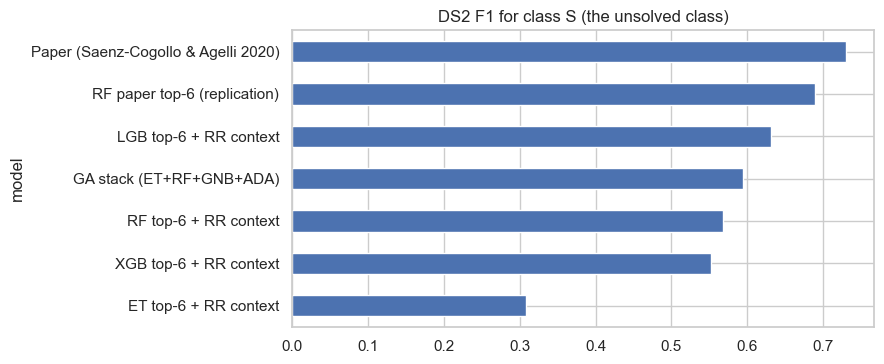

In [ ]:
def score_row(name, pred):
    f = f1_score(test1.label, pred, labels=['N', 'S', 'V'], average=None, zero_division=0)
    s = (test1.label == 'S').values; r = (test1.record == REC_S_HEAVY).values
    return dict(model=name, acc=(pred == test1.label.values).mean(), F1_N=f[0], F1_S=f[1], F1_V=f[2], macro_NSV=f.mean(),
                S_rec_heavy=(pred[s & r] == 'S').mean() if (s & r).any() else np.nan,
                S_rec_other=(pred[s & ~r] == 'S').mean() if (s & ~r).any() else np.nan)

final_cfgs = [('RF paper top-6 (replication)', MODELS['RF'], base6),
              ('RF top-6 + RR context',         MODELS['RF'], base6 + CTX),
              ('ET top-6 + RR context',         MODELS['ET'], base6 + CTX),
              ('XGB top-6 + RR context',        MODELS['XGB'], base6 + CTX),
              ('LGB top-6 + RR context',        MODELS['LGB'], base6 + CTX)]
final_rows, final_preds = [], {}
for name, mk, cols in final_cfgs:
    row, pred = eval_ds2(mk, cols, name, verbose=False)
    ds1 = lopo_log.get(name) or lopo(mk, cols, tag=name)
    row['DS1_LOPO_macro'] = ds1['macroF1_NSV']
    final_rows.append(row); final_preds[name] = pred

meta = LogisticRegression(max_iter=2000).fit(np.hstack([oof[k] for k in chosen]), ytr)
Zte = np.hstack([pool[k].fit(X13, ytr).predict_proba(test1[COLS13]) for k in chosen])
pred_stack = pd.Series(meta.predict(Zte)).map(inv).values
row = score_row('GA stack (' + '+'.join(chosen) + ')', pred_stack); row['DS1_LOPO_macro'] = bf
final_rows.append(row); final_preds[row['model']] = pred_stack

paper = dict(model='Paper (Saenz-Cogollo & Agelli 2020)', acc=0.9614, F1_N=0.9797, F1_S=0.7306, F1_V=0.9085)
paper['macro_NSV'] = np.mean([paper['F1_N'], paper['F1_S'], paper['F1_V']])
final = pd.DataFrame([paper] + final_rows).set_index('model')
cols_show = ['DS1_LOPO_macro', 'acc', 'F1_N', 'F1_S', 'F1_V', 'macro_NSV', 'S_rec_heavy', 'S_rec_other']
display(final[cols_show].round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
final.F1_S.sort_values().plot.barh(ax=ax, title='DS2 F1 for class S (the unsolved class)')
plt.tight_layout()
plt.show()

### 11.1 Robustness check A: leave-one-patient-out over all 44 records (supplementary)

DS2 records are used in training folds here, so this is **not an independent test**; it only shows whether the context features help or hurt across *all* patients, including record 232.

In [ ]:
allb = pd.concat([train1, test1[test1.label.isin(['N', 'S', 'V'])]], ignore_index=True)
ya, ga = allb.label.map(lab).values, allb.record.values
rows44 = {}
for name, mk, cols in [('RF base6', MODELS['RF'], base6), ('RF base6+ctx', MODELS['RF'], base6 + CTX),
                       ('LGB base6', MODELS['LGB'], base6), ('LGB base6+ctx', MODELS['LGB'], base6 + CTX)]:
    p = cross_val_predict(mk(), allb[cols], ya, groups=ga, cv=LeaveOneGroupOut())
    f = f1_score(ya, p, labels=[0, 1, 2], average=None, zero_division=0)
    rows44[name] = dict(macro_NSV=f.mean(), F1_N=f[0], F1_S=f[1], F1_V=f[2])
display(pd.DataFrame(rows44).T.round(4))

,macro_NSV,F1_N,F1_S,F1_V
RF base6,0.7777,0.9802,0.4790,0.8739
RF base6+ctx,0.7502,0.9794,0.3949,0.8763
LGB base6,0.7803,0.9794,0.4918,0.8696
LGB base6+ctx,0.7575,0.9789,0.4190,0.8747


### 11.2 Robustness check B: how much of a DS2 difference is noise? Bootstrap over records
Resample the DS2 *records* (not beats) with replacement and recompute S F1, because beats from one patient are strongly correlated.

In [ ]:
nm_a, nm_b = 'RF paper top-6 (replication)', 'LGB top-6 + RR context'
pa, pb = final_preds[nm_a], final_preds[nm_b]
yt, rec = test1.label.values, test1.record.values
recs = np.unique(rec); idx = {r: np.where(rec == r)[0] for r in recs}; rng = np.random.default_rng(0)
boot = []
for _ in range(500):
    take = np.concatenate([idx[r] for r in rng.choice(recs, len(recs))])
    boot.append([f1_score(yt[take], p[take], labels=['S'], average=None, zero_division=0)[0] for p in (pa, pb)])
boot = np.array(boot)
print('S F1 95% interval over records:', nm_a, np.percentile(boot[:, 0], [2.5, 97.5]).round(3),
      '|', nm_b, np.percentile(boot[:, 1], [2.5, 97.5]).round(3))
print('P(second model better on S):', (boot[:, 1] > boot[:, 0]).mean().round(2))

S F1 95% interval over records: RF paper top-6 (replication) [0.111 0.859] | LGB top-6 + RR context [0.215 0.758]
P(second model better on S): 0.32


In [ ]:
sdf = test1[test1.label == 'S'].assign(hit=lambda d: (final_preds[nm_a][d.index] == 'S'))
per_rec = sdf.groupby('record').agg(n_S=('hit', 'size'), recall_RF_replication=('hit', 'mean')).sort_values('n_S', ascending=False)
display(per_rec.head(8).round(3))

,n_S,recall_RF_replication
record,,
232,1360,0.858
222,209,0.952
202,55,0.382
234,50,0.000
100,32,1.000
200,30,0.000
213,28,0.321
210,22,0.000


SHAP summary for class S (replication RF, DS2 sample):


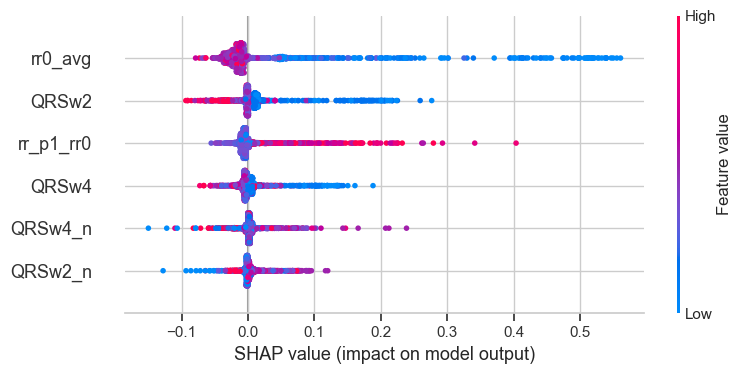

,mean_|SHAP|_S
rr0_avg,0.0416
QRSw2,0.0174
rr_p1_rr0,0.0140
QRSw4,0.0112
QRSw4_n,0.0084
QRSw2_n,0.0079


In [ ]:
rf_rep = MODELS['RF']().fit(train1[base6], ytr)
X_te_shap = test1[base6].sample(min(2000, len(test1)), random_state=0)
explainer_rep = shap.TreeExplainer(rf_rep)
sv_rep = explainer_rep.shap_values(X_te_shap)

if isinstance(sv_rep, list):
    sv_s = np.asarray(sv_rep[lab['S']])
elif np.asarray(sv_rep).ndim == 3:
    sv_s = np.asarray(sv_rep)[:, :, lab['S']]
else:
    sv_s = np.asarray(sv_rep)

print('SHAP summary for class S (replication RF, DS2 sample):')
shap.summary_plot(sv_s, X_te_shap, show=False)
plt.tight_layout()
plt.show()

mean_abs_s = pd.Series(np.abs(sv_s).mean(axis=0), index=base6).sort_values(ascending=False)
display(mean_abs_s.round(4).to_frame('mean_|SHAP|_S'))

In [ ]:
rf_ctx = MODELS['RF']().fit(train1[base6 + CTX], ytr)
s_df = test1[test1.label == 'S'].copy()
s_232 = s_df[s_df.record == REC_S_HEAVY][base6 + CTX].sample(min(400, (s_df.record == REC_S_HEAVY).sum()), random_state=0)
s_oth = s_df[s_df.record != REC_S_HEAVY][base6 + CTX].sample(min(400, (s_df.record != REC_S_HEAVY).sum()), random_state=0)

exp_ctx = shap.TreeExplainer(rf_ctx)
def s_shap(df_sub):
    vals = exp_ctx.shap_values(df_sub)
    if isinstance(vals, list):
        return np.asarray(vals[lab['S']])
    arr = np.asarray(vals)
    return arr[:, :, lab['S']] if arr.ndim == 3 else arr

comp_shap = pd.DataFrame({
    f'mean_|SHAP|_rec{REC_S_HEAVY}': np.abs(s_shap(s_232)).mean(axis=0),
    'mean_|SHAP|_other_S': np.abs(s_shap(s_oth)).mean(axis=0)
}, index=base6 + CTX).sort_values(f'mean_|SHAP|_rec{REC_S_HEAVY}', ascending=False)
display(comp_shap.round(4))

,mean_|SHAP|_rec232,mean_|SHAP|_other_S
rr0_avg,0.2921,0.1437
QRSw4,0.0551,0.0539
QRSw2,0.0537,0.0560
rmssd8_rel,0.0465,0.0352
std8_rel,0.0246,0.0316
QRSw2_n,0.0181,0.0200
pause_next,0.0156,0.0239
QRSw4_n,0.0152,0.0237
premat,0.0142,0.0717
rr_p1_rr0,0.0127,0.0493


## 12. Conclusions and limitations

**Storyline for the report.**
1. **Formulation matters more than the model.** Our first formulation (heart-rate classes) gave 97-100% accuracy that was pure label leakage; without the leaking features there was no signal. Moving to AAMI beat classification gave a meaningful task.
2. **Evaluation protocol decides the numbers.** Random beat splits would have given 98-99%. The inter-patient split, record 222 in DS2, training on N/S/V only and counting F and Q as errors changed the results substantially. Several "problems" were bugs (QRS columns not in the feature list, a duplicated record, a missing record), caught by comparing supports and counts with the paper.
3. **Replication succeeded.** RF with the paper's top-6 features (normalised QRS widths and RR features) reaches DS2 F1 N/S/V = 0.977 / 0.694 / 0.901 against the paper's 0.980 / 0.731 / 0.909. Patient-relative QRS widths were the decisive feature family: they cut the false V from bundle-branch-block patients from 2,643 to 153.
4. **Extensions gave no reliable gain.** RR-context features improved DS1 LOPO slightly but hurt S on DS2 and in the 44-record LOPO; patient-relative shape features helped V and hurt S; boosting and GA stacking did not beat a plain RF with the paper's features. Giving models *more* patient-specific features made generalisation to new patients *worse*.
5. **Class S is the unsolved part and it is patient-dependent.** One patient (record 232) holds 83% of DS2's S beats, one (record 209) 41% of DS1's. Any single S score is fragile, and model rankings on DS1 and DS2 disagree on S.

**What we can claim:** a working replication of an inter-patient RF heartbeat classifier; a documented negative result for four extensions with a testable mechanism for one of them; an evaluation methodology (grouped CV, per-record breakdowns, bootstrap over records) that exposes how patient-dependent the minority classes are.

**Limitations.**
* The QRS/amplitude extraction follows our reading of Appendix A; some steps were ambiguous (sign handling for negative QRS, the Q-peak step f) and it was not compared with the authors' code. It was smoke-tested on simulated ECG only for `QRSw2` / `QRSw4`; `QRSw`, `PRd` and the P-wave features were unreliable in that test (mean-subtracted baseline makes the zero-crossing rule fragile).
* Cap of 200 ms on widths and the choice of 8 / 32-beat windows are our own design choices.
* Models were selected on DS1 only, but DS2 error analysis (records 214, 219, 232) informed what we tried next. Those later changes were evaluated on DS2 as well, so DS2 is not a fully untouched test set. The 44-record LOPO is supplementary and not independent.
* MIT-BIH has 47 patients; one lead; many patients have no S or F beats. Cross-database validation (INCART, SVDB) was not done.
* The `premat` contamination mechanism for record 232 and the bootstrap intervals are specified but not yet run.

**Reproducing.** Run the notebook top to bottom (cells are cached in `artifacts/`, set `FORCE_REBUILD = True` to recompute). Seeds are fixed (`random_state=0`). Full run: feature extraction a few minutes (parallel), LOPO sweeps and OOF probabilities 20-40 minutes, GA exhaustive check about 10-15 minutes.

**References.** Saenz-Cogollo & Agelli (2020), *Algorithms* 13(4):75; Zou et al. (2022), *IEEE J. Transl. Eng. Health Med.* 10:1900508; Zhao et al. (2024), *Biomed. Signal Process. Control* 87:105506; Jaya Prakash et al. (2025), *Front. Digit. Health* 7:1649923; Chen et al. (2024), *IEEE Trans. Biomed. Eng.* 71(7); de Chazal et al. (2004), *IEEE Trans. Biomed. Eng.* 51(7):1196; Moody & Mark (2001), *IEEE Eng. Med. Biol. Mag.* 20(3):45.